# Tuning, seleção e threshold

**Tarefas:** T3.x · **Dono:** _(a definir)_

Bancada de trabalho: a lógica reutilizável fica em `src/`; aqui corre-se, explora-se e
guarda-se o que o `Projeto_Final.ipynb` vai ler (`reports/experiments.csv`, `reports/figures/`).
Regras da modelação: [docs/modelacao_base.md](../docs/modelacao_base.md).

O teste (`data.X_test`) **só se abre uma vez**, na avaliação final (T3.6).

**Modelo v1: HistGradientBoosting** (F2·1). Tudo o que se segue usa as previsões OOF do treino.

In [1]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)  # os caminhos de src/ (data/, reports/, models/) são relativos à raiz

import matplotlib.pyplot as plt
import pandas as pd

from src.models.baselines import candidate_models
from src.models.threshold import (CAPACITIES, capacity_table, confusion_at_k, gains_curve,
                                  rank_baseline_at_k)
from src.models.train import run_cv
from src.pipeline import load_model_data

data = load_model_data()
FIG = ROOT / "reports" / "figures"
BASE_RATE = data.y_train.mean()

## 3.4 Tuning (poucas combinações por modelo)

In [2]:
# TODO: grelha pequena para o HistGradientBoosting; cada combinação via run_cv(..., notes="T3 tuning")

## 3.4 Desequilíbrio (T3.1)

Sem experiência nova. Para o relatório: com 11,34% de positivos, pesar as classes não mudou a ordenação (regressão logística com `class_weight="balanced"`: PR-AUC 0,208 contra 0,210 sem pesos, nos mesmos 5 folds). O desequilíbrio trata-se na escolha das métricas (PR-AUC, recall@k) e do corte pela capacidade.

## 3.5 Seleção: modelo v1 e previsões OOF

HistGradientBoosting (F2·1): empatado com o XGBoost na CV e sem dependências novas. As OOF são o score de cada encontro de treino quando estava na validação. Ficam em `reports/oof_v1.csv` para o `05` e o `06`; a corrida já está no registo (notebook 03), por isso não se regista outra vez.

In [3]:
best = candidate_models()["hist_gradient_boosting"]
val_folds, oof = run_cv("hist_gradient_boosting", best, data, log=False, return_oof=True)
oof.to_frame().to_csv(ROOT / "reports" / "oof_v1.csv", index=False)
val_folds[["pr_auc", "roc_auc", "recall_at_10", "recall_at_20", "brier"]].agg(["mean", "std"]).round(3)

,pr_auc,roc_auc,recall_at_10,recall_at_20,brier
mean,0.234,0.677,0.247,0.40,0.095
std,0.008,0.008,0.014,0.01,0.000


## Ablação (F2·2): payer_code, max_glu_serum e indicador de registo incompleto

Critério decidido na F2·2: uma coluna **fica só se a PR-AUC com ela for maior do que sem ela por mais do que o desvio entre folds** do modelo v1. Mesmos 5 folds de D13; a comparação é feita fold a fold (Δ = variante − v1). O indicador de D5 vale 1 quando algum dos três IDs de admissão/alta é `Desconhecido` (15,1% dos encontros).

In [4]:
from dataclasses import replace

from src.features.build import incomplete_record
from src.models.baselines import hist_gradient_boosting

data_ind = replace(data, X_train=data.X_train.assign(incomplete_record=incomplete_record(data.X_train)),
                   X_test=data.X_test.assign(incomplete_record=incomplete_record(data.X_test)))
variants = {
    "sem payer_code": (hist_gradient_boosting(exclude=["payer_code"]), data),
    "sem max_glu_serum": (hist_gradient_boosting(exclude=["max_glu_serum"]), data),
    "com indicador de registo incompleto": (hist_gradient_boosting(extra_binary=["incomplete_record"]), data_ind),
}
sd_v1 = val_folds["pr_auc"].std()
rows = []
for name, (model, d) in variants.items():
    folds = run_cv(f"hgb ablação: {name}", model, d, notes="F2·2 ablação")
    delta = folds["pr_auc"] - val_folds["pr_auc"]
    # Remoção: a coluna fica se tirá-la piora mais do que o desvio. Indicador: entra se melhora mais do que o desvio.
    adds = name.startswith("com")
    keep = (delta.mean() > sd_v1) if adds else (-delta.mean() > sd_v1)
    rows.append({"variante": name, "pr_auc": folds["pr_auc"].mean(), "delta_medio": delta.mean(),
                 "delta_std": delta.std(), "folds_melhor": int((delta > 0).sum()),
                 "decisao": ("entra" if keep else "não entra") if adds else ("fica" if keep else "sai")})
ablation = pd.DataFrame(rows).set_index("variante")
ablation.to_csv(ROOT / "reports" / "ablation_f2_2.csv")
print(f"Modelo v1 (34 features): PR-AUC {val_folds['pr_auc'].mean():.4f}, desvio entre folds {sd_v1:.4f}")
ablation.round(4)

Modelo v1 (34 features): PR-AUC 0.2345, desvio entre folds 0.0081


,pr_auc,delta_medio,delta_std,folds_melhor,decisao
variante,,,,,
sem payer_code,0.2307,-0.0038,0.0029,0,sai
sem max_glu_serum,0.2341,-0.0003,0.0020,2,sai
com indicador de registo incompleto,0.2342,-0.0002,0.0018,2,não entra


## 3.3 Threshold pela capacidade (B1, B2)

Um corte por capacidade k: o quantil (1 − k) das OOF. Sem tiers.

In [5]:
cap = capacity_table(data.y_train, oof)
cap.round(4)

,threshold,n_sinalizados,pct_sinalizados,recall,precision,lift,readm_por_100_followups,readm_encontradas_por_1000_altas
k,,,,,,,,
0.1,0.2003,8005,0.1,0.2472,0.2803,2.4722,28.0325,28.0356
0.2,0.1524,16009,0.2,0.3994,0.2264,1.9969,22.6435,45.2893


## Comparação à mesma capacidade (B3)

`number_inpatient` ordenado com desempate aleatório (média de 20 sorteios) e ordem ao acaso (`DummyClassifier(strategy="prior")`: score constante, por isso recall@k = k).

In [6]:
rows = []
for k in CAPACITIES:
    b = rank_baseline_at_k(data.y_train, data.X_train["number_inpatient"], k)
    for method, rec, prec in [("Modelo v1", cap.loc[k, "recall"], cap.loc[k, "precision"]),
                              ("Ordenar por number_inpatient", b["recall_mean"], b["precision_mean"]),
                              ("Ao acaso", k, BASE_RATE)]:
        rows.append({"k": k, "metodo": method, "recall": rec, "precision": prec,
                     "readm_por_1000_altas": 1000 * k * prec})
comp = pd.DataFrame(rows).set_index(["k", "metodo"])
rule = (data.X_train["number_inpatient"] >= 1).mean()
print(f"Regra number_inpatient >= 1: sinaliza {rule:.1%} das altas (não é comparável a 10% ou 20%).")
comp.round(3)

Regra number_inpatient >= 1: sinaliza 33.3% das altas (não é comparável a 10% ou 20%).


recall  precision  readm_por_1000_altas
k   metodo                                                               
0.1 Modelo v1                      0.247      0.280                28.032
    Ordenar por number_inpatient   0.209      0.237                23.676
    Ao acaso                       0.100      0.113                11.339
0.2 Modelo v1                      0.399      0.226                45.287
    Ordenar por number_inpatient   0.342      0.194                38.781
    Ao acaso                       0.200      0.113                22.678

## Matrizes de confusão a 10% e 20% (B4)

In [7]:
for k in CAPACITIES:
    c = confusion_at_k(data.y_train, oof, k)
    m = pd.DataFrame(c["matrix"], index=["real 0", "real 1"], columns=["sem follow-up", "follow-up"])
    m.to_csv(ROOT / "reports" / f"confusion_k{int(k * 100)}.csv")
    display(m.rename_axis(f"k = {k:.0%}"))

,sem follow-up,follow-up
k = 10%,,
real 0,65204,5761
real 1,6832,2244


,sem follow-up,follow-up
k = 20%,,
real 0,58581,12384
real 1,5451,3625


## Curva de ganhos (B5)

Regras IBCS da W8: mensagem primeiro, depois o título em três linhas (quem, o quê, quando); eixos a partir de zero; rótulos nos pontos em vez de grelha; métodos identificados no fim das linhas, sem legenda.

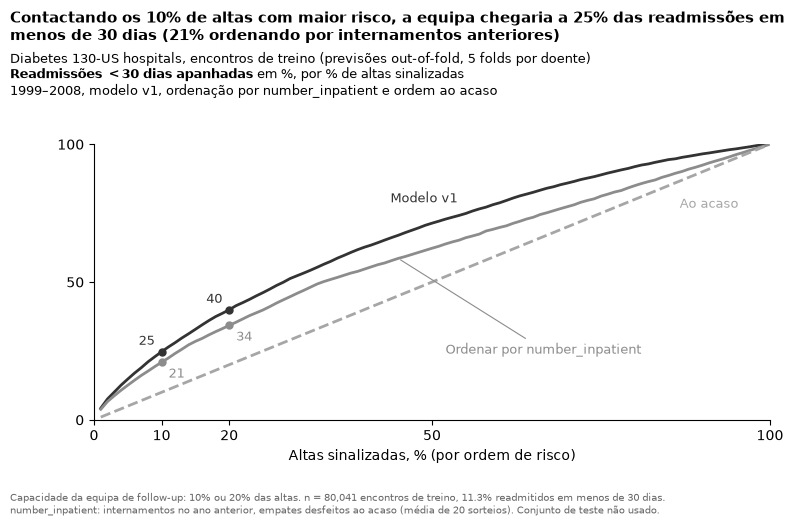

In [8]:
g_model = gains_curve(data.y_train, oof)
g_inp = gains_curve(data.y_train, data.X_train["number_inpatient"], n_draws=20)
x10 = g_model.loc[g_model["k"].round(2) == 0.10, "pct_readm_apanhadas"].iat[0]
b10 = g_inp.loc[g_inp["k"].round(2) == 0.10, "pct_readm_apanhadas"].iat[0]

fig, ax = plt.subplots(figsize=(8, 5.2))
g_rand = pd.DataFrame({"k": g_model["k"], "pct_readm_apanhadas": 100 * g_model["k"]})
# (curva, rótulo, cor, estilo, posição do rótulo junto à linha: x em %, deslocamento em pontos)
lines = [(g_model, "Modelo v1", "#333333", "-", 55, (-6, 8), "right"),
         (g_inp, None, "#8c8c8c", "-", None, None, None),
         (g_rand, "Ao acaso", "#a6a6a6", "--", 85, (8, -16), "left")]
at = lambda g, k: g.loc[(100 * g["k"]).round() == k, "pct_readm_apanhadas"].iat[0]
for g, label, color, ls, xk, off, ha in lines:
    ax.plot(100 * g["k"], g["pct_readm_apanhadas"], color=color, ls=ls, lw=2)
    if label:
        ax.annotate(label, (xk, at(g, xk)), xytext=off, textcoords="offset points", ha=ha, fontsize=9, color=color)
# Sem espaço entre as duas linhas cinzentas: rótulo em baixo, com linha de chamada.
ax.annotate("Ordenar por number_inpatient", (45, at(g_inp, 45)), xytext=(52, 24), textcoords="data",
            fontsize=9, color="#8c8c8c", arrowprops=dict(arrowstyle="-", color="#8c8c8c", lw=0.8))
for k in (10, 20):
    for g, color, off, ha in [(g_model, "#333333", (-5, 5), "right"), (g_inp, "#8c8c8c", (5, -11), "left")]:
        y = at(g, k)
        ax.plot(k, y, "o", color=color, ms=5)
        ax.annotate(f"{y:.0f}", (k, y), xytext=off, textcoords="offset points", ha=ha, fontsize=9, color=color)
ax.set_xlim(0, 100); ax.set_ylim(0, 100)
ax.set_xticks([0, 10, 20, 50, 100]); ax.set_yticks([0, 50, 100])
ax.spines[["top", "right"]].set_visible(False)
ax.set_xlabel("Altas sinalizadas, % (por ordem de risco)")
fig.text(0.02, 0.98, f"Contactando os 10% de altas com maior risco, a equipa chegaria a {x10:.0f}% das readmissões "
         f"em menos de 30 dias ({b10:.0f}% ordenando por internamentos anteriores)",
         fontsize=10.5, fontweight="bold", va="top", wrap=True)
fig.text(0.02, 0.90, "Diabetes 130-US hospitals, encontros de treino (previsões out-of-fold, 5 folds por doente)\n"
         r"$\bf{Readmissões\ <30\ dias\ apanhadas}$ em %, por % de altas sinalizadas" "\n"
         "1999–2008, modelo v1, ordenação por number_inpatient e ordem ao acaso", fontsize=9, va="top")
fig.text(0.02, 0.01, f"Capacidade da equipa de follow-up: 10% ou 20% das altas. n = {len(oof):,} encontros de treino, "
         f"{BASE_RATE:.1%} readmitidos em menos de 30 dias.\n"
         "number_inpatient: internamentos no ano anterior, empates desfeitos ao acaso (média de 20 sorteios). "
         "Conjunto de teste não usado.", fontsize=7.5, color="#666666")
fig.subplots_adjust(top=0.72, bottom=0.19, right=0.97)
fig.savefig(FIG / "gains_curve_v1.png", dpi=150)
plt.show()

## 3.6 Avaliação final no teste (uma vez)

Só depois de fechadas F2·2, P12 e o tuning. Com os thresholds do `config.json` (B6): reportar a fração de altas realmente sinalizada no teste e assinalar na coluna `note` se diferir de k em mais de 1 pp.

In [9]:
# from src.models.train import fit_final, load_model
# bundle = load_model()
# test_scores = predict_scores(bundle["model"], data.X_test)
# for k in (10, 20):
#     share = (test_scores >= bundle[f"threshold_k{k}"]).mean()
#     print(k, share, "ATENÇÃO" if abs(share - k / 100) > 0.01 else "")